# MorphoNup — all datasets

Status of every dataset × k, and the cross-dataset benchmark tables and figures (refit, mean ± SD over the finished seeds). Training is started from `01_Train_MorphoNup.ipynb` or `scripts/run_cv.py`; this notebook only reads results.

In [1]:
K_LIST = [5, 10]
SEEDS = [151000, 152000, 153000]

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
_null, _err = os.open(os.devnull, os.O_WRONLY), os.dup(2)
os.dup2(_null, 2)                                    # TensorFlow's CUDA start-up lines go to C-level stderr
try:
    import tensorflow  # noqa: F401
finally:
    os.dup2(_err, 2)
    os.close(_null)
    os.close(_err)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "morphonup" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display

from morphonup import config, figures, jobs
from morphonup.cv import run_dir

pd.set_option("display.width", 200, "display.max_columns", 40)


def show(path, width=900):
    """Display a saved figure with its caption (from the folder's figure_catalog.csv)."""
    path = Path(path)
    if not path.exists():
        print("missing:", path.relative_to(ROOT))
        return
    cat = path.parent / "figure_catalog.csv"
    caption = pd.read_csv(cat).set_index("png").suggested_caption.get(path.name, "") if cat.exists() else ""
    display(Markdown(f"**{path.stem}** — `{path.relative_to(ROOT)}`  \n{caption}"))
    display(Image(filename=str(path), width=width))

gpu, procs = jobs.gpu_status()
print("GPU:", gpu, "| processes:", procs or "none")
print("MorphoNup jobs running:", jobs.running_jobs() or "none")

GPU: NVIDIA GeForce RTX 4070 Ti, 0 %, 1 MiB, 12282 MiB | processes: none
MorphoNup jobs running: none


## Status

In [3]:
status = pd.concat([jobs.progress(d, k, SEEDS) for d in config.DATASETS for k in K_LIST], ignore_index=True)
overview = (status.assign(done=status.status.eq("done"), started=status.status.eq("started"))
            .groupby(["dataset", "k"], sort=False)[["done", "started"]].sum().unstack("k"))
display(overview)

done    started   
k                                          5  10      5  10
dataset                                                    
DatasetNup_1/Homo_sapiens                   3  3       0  0
DatasetNup_1/Caenorhabditis_elegans         3  3       0  0
DatasetNup_1/Drosophila_melanogaster        0  0       0  0
DatasetNup_3/Homo_sapiens_hg38              0  0       0  0
DatasetNup_2/Drosophila_melanogaster/5U     0  0       0  0
DatasetNup_2/Homo_sapiens/5U                0  0       0  0
DatasetNup_2/Saccharomyces_cerevisiae/PM    0  0       0  0
DatasetNup_2/Saccharomyces_cerevisiae/WG    0  0       0  0
DatasetNup_2/Drosophila_melanogaster/LC     0  0       0  0
DatasetNup_2/Drosophila_melanogaster/PM     0  0       0  0
DatasetNup_2/Homo_sapiens/PM                0  0       0  0
DatasetNup_2/Homo_sapiens/LC                0  0       0  0

## Benchmark

In [4]:
drawn = figures.benchmark_figures(config.RESULTS_ROOT)
table = config.RESULTS_ROOT / "benchmark" / "benchmark_table.md"
display(Markdown(table.read_text()) if table.exists() else Markdown("_No finished dataset yet._"))

# MorphoNup benchmark (refit, arm `full`): mean ± SD over seeds

| Dataset | k | N | Nuc. fraction | Seeds | Accuracy | Balanced acc. | MCC | ROC AUC | PR AUC |
|---|---|---|---|---|---|---|---|---|---|
| DatasetNup_1/Homo_sapiens | 5 | 4,573 | 0.50 | 3 | 0.8910 ± 0.0003 | 0.8912 ± 0.0003 | 0.7829 ± 0.0006 | 0.9467 ± 0.0005 | 0.9414 ± 0.0006 |
| DatasetNup_1/Homo_sapiens | 10 | 4,573 | 0.50 | 3 | 0.8888 ± 0.0016 | 0.8889 ± 0.0016 | 0.7785 ± 0.0032 | 0.9481 ± 0.0005 | 0.9444 ± 0.0012 |
| DatasetNup_1/Caenorhabditis_elegans | 5 | 5,175 | 0.50 | 3 | 0.8602 ± 0.0002 | 0.8604 ± 0.0003 | 0.7223 ± 0.0012 | 0.9284 ± 0.0010 | 0.9120 ± 0.0017 |
| DatasetNup_1/Caenorhabditis_elegans | 10 | 5,175 | 0.50 | 3 | 0.8623 ± 0.0021 | 0.8625 ± 0.0021 | 0.7264 ± 0.0042 | 0.9301 ± 0.0007 | 0.9156 ± 0.0008 |


**heatmap_k5** — `results/benchmark/figures/heatmap_k5.png`  
MorphoNup (refit) on every dataset, outer 5-fold CV: mean over seeds of the pooled out-of-fold metrics (threshold 0.5). Rows sorted by dataset size.

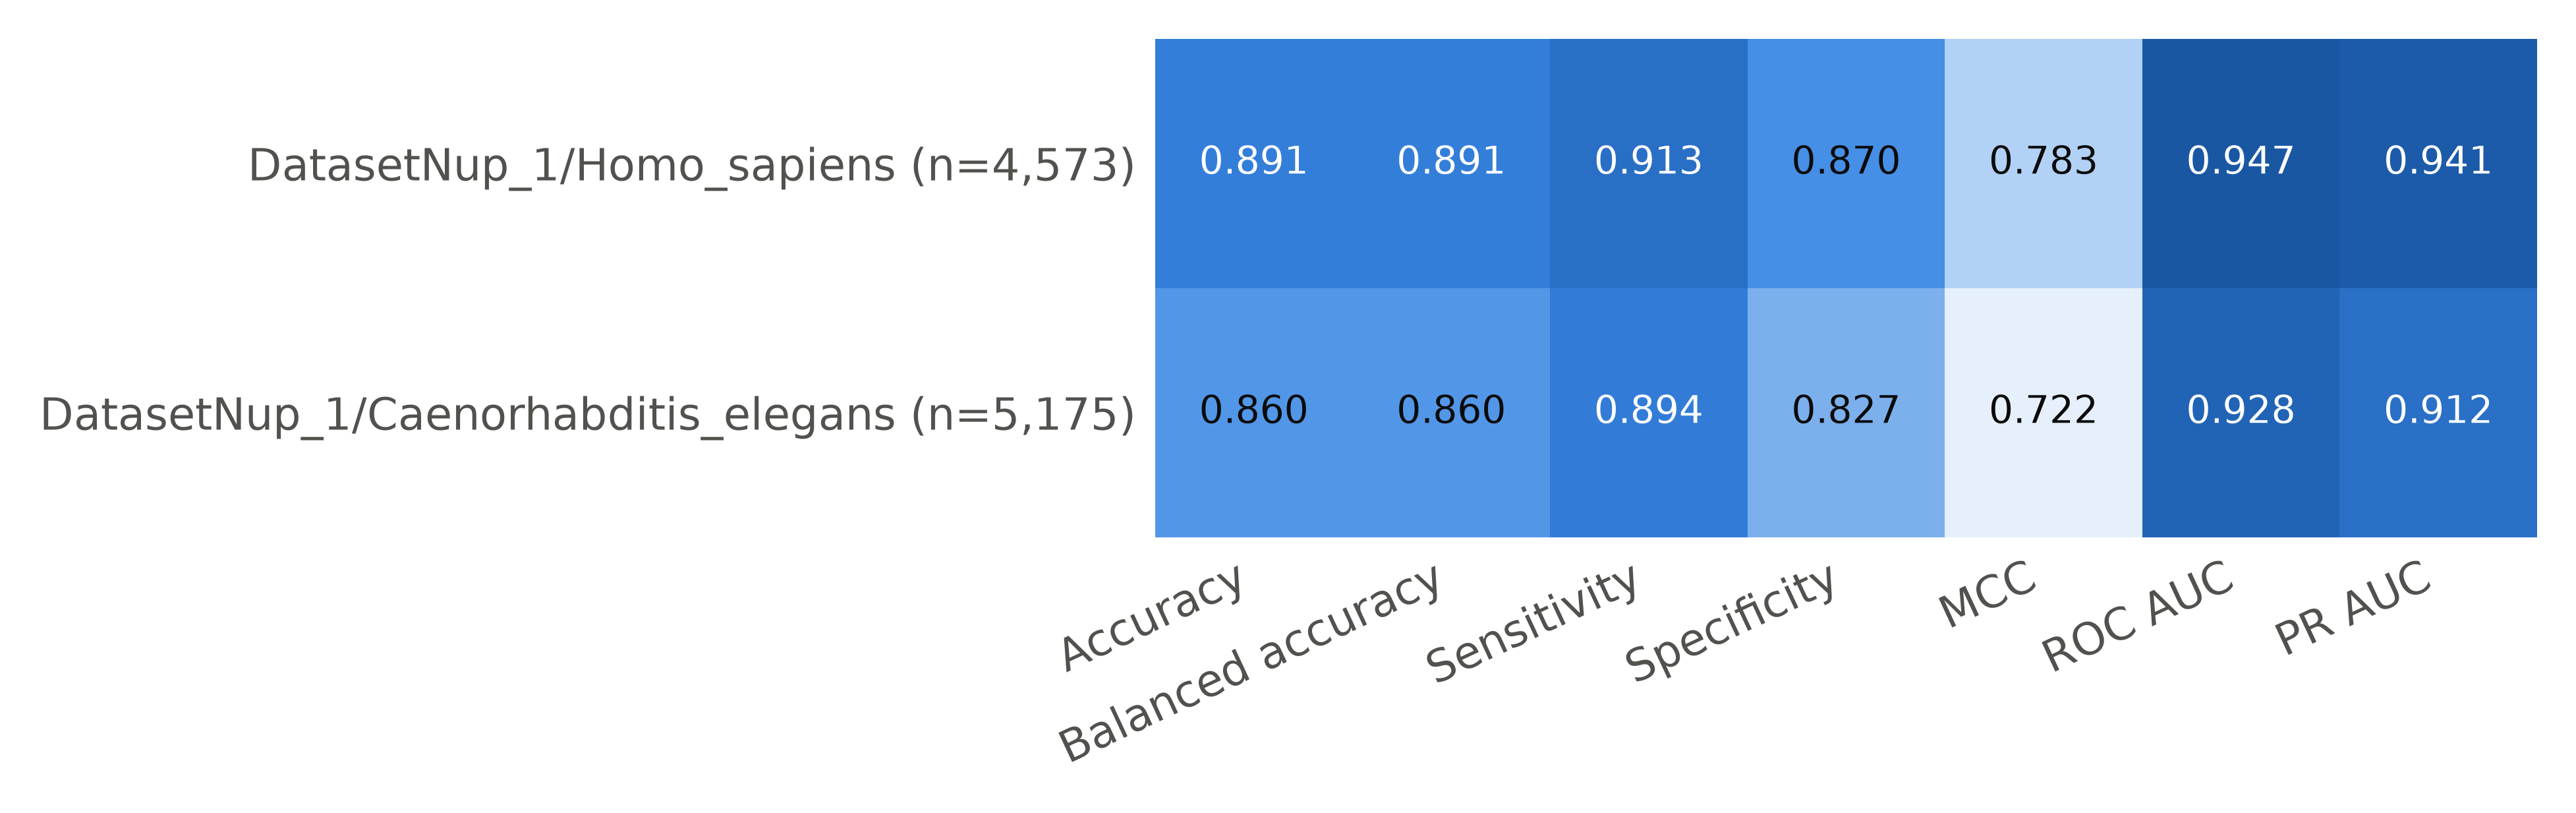

**heatmap_k10** — `results/benchmark/figures/heatmap_k10.png`  
MorphoNup (refit) on every dataset, outer 10-fold CV: mean over seeds of the pooled out-of-fold metrics (threshold 0.5). Rows sorted by dataset size.

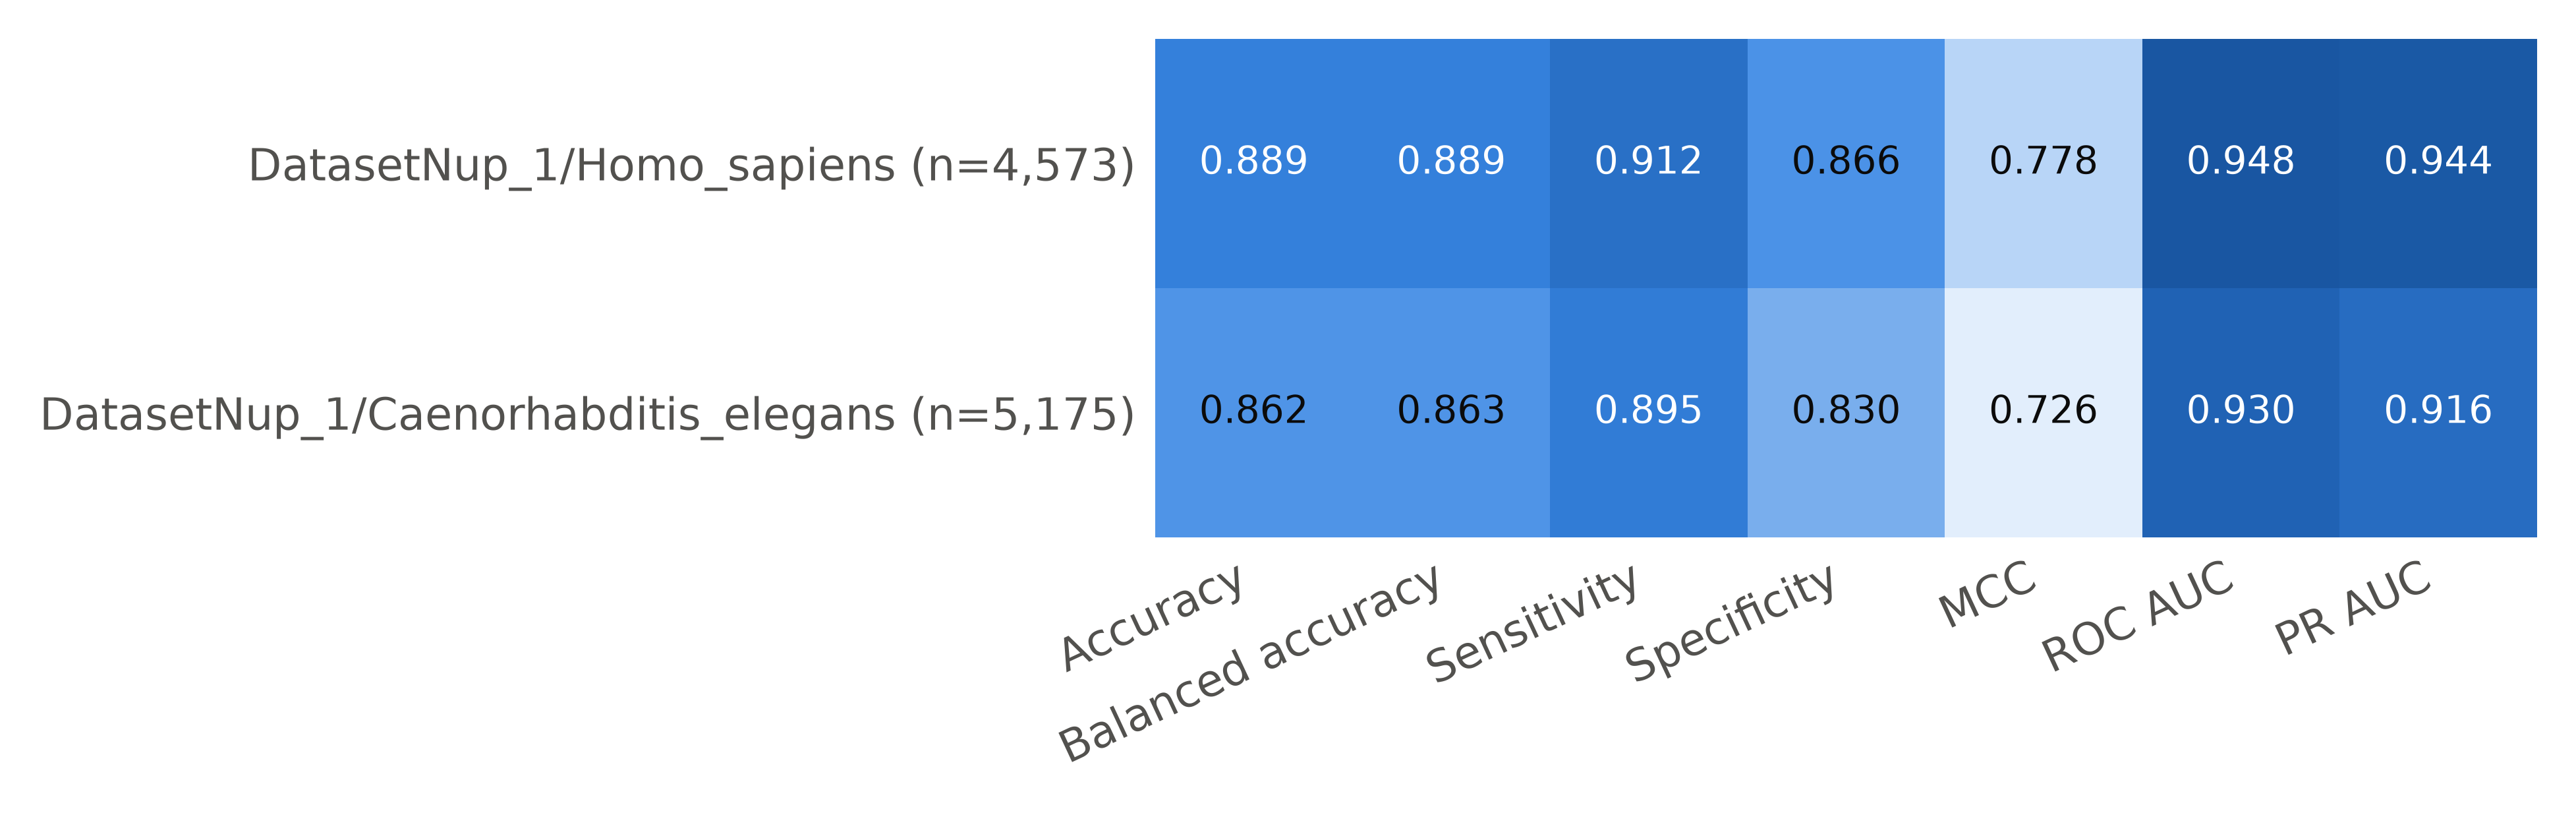

**k_comparison** — `results/benchmark/figures/k_comparison.png`  
MorphoNup (refit): pooled out-of-fold accuracy and MCC at each k (mean ± SD over seeds; no bar = one seed). Lines join the same dataset.

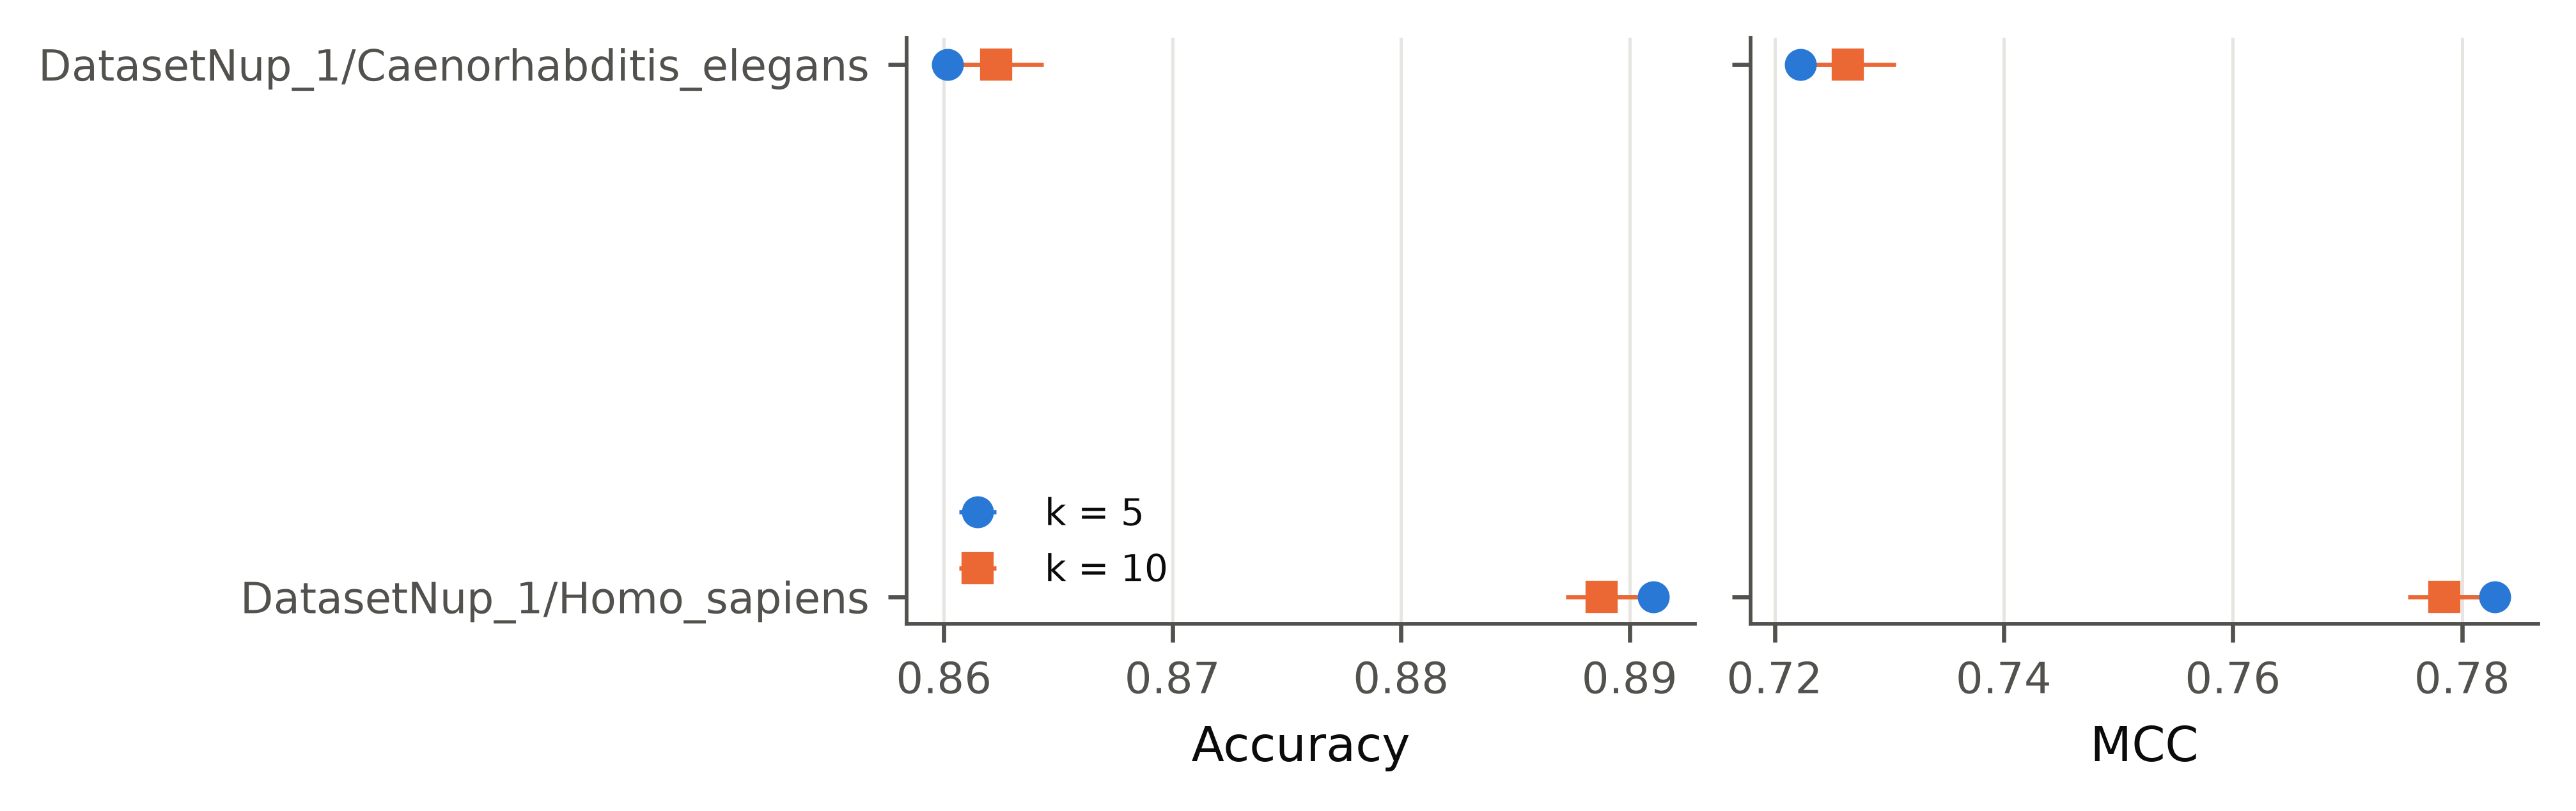

In [5]:
BENCH = config.RESULTS_ROOT / "benchmark" / "figures"
for k in K_LIST:
    if (BENCH / f"heatmap_k{k}.png").exists():
        show(BENCH / f"heatmap_k{k}.png")
    else:
        print(f"k={k}: no finished dataset yet")
if (BENCH / "k_comparison.png").exists():
    show(BENCH / "k_comparison.png")
else:
    print("k comparison: needs a dataset finished at both k")